# Capítulo 3 · Actividad: análisis de datos con NumPy, pandas y matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/01_actividad_numpy_pandas.ipynb)

En esta actividad haces de **analista de datos**: vas a responder preguntas sobre datos reales con **NumPy** y **pandas**, y después los visualizarás con **matplotlib** y **seaborn**. Lo importante no es solo que el código funcione, sino que **sepas interpretar los resultados**.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia. Si editas el original tendrás conflictos al sincronizar tu fork.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```
3. Ten a mano las notebooks de clase de `notebooks/lectures/chapter_03/`: `01_numpy`, `02_pandas` y `03_matplotlib`.

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Puedes añadir todas las celdas que necesites.
- En las celdas ✍️ responde con tus palabras y **apoya tus respuestas con números** de tus resultados.
- En las partes 1 y 2, las 💡 **pistas** te recuerdan funciones. Si una función no salió en clase, la pista explica cómo usarla. La parte 3 no tiene pistas.
- Al terminar, ejecuta **Kernel → Restart & Run All** y comprueba que todo funciona de arriba abajo.

| Parte | Datos | Herramienta |
|---|---|---|
| 1. La cafetería | ventas de un mes (generadas en la notebook) | NumPy |
| 2. Las propinas | `data/tips.csv` | pandas (+ un poco de NumPy) |
| 3. Visualización | cafetería, propinas y `data/penguins.csv` | matplotlib y seaborn |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: C:\Users\alexa\Desktop\ml-coursey\data


---
## Parte 1 · La cafetería ☕ (NumPy)

Una cafetería vende 5 productos y ha registrado cuántas unidades vendió de cada uno durante **4 semanas** (28 días, de lunes a domingo). La dueña quiere saber cuánto gana, qué días van mejor y qué producto le conviene más.

Ejecuta la siguiente celda para generar los datos. **No hace falta que la modifiques ni que entiendas cada línea.**

In [2]:
# Datos de la cafetería (no hace falta modificar esta celda)
rng = np.random.default_rng(42)

productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])       # precio de cada producto, en $

# Unidades vendidas cada día: los fines de semana se vende un 50% más
dia_semana = np.tile(np.arange(7), 4)                # 0 = lunes, ..., 6 = domingo
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])     # ventas esperadas por día y producto
ventas_planas = rng.poisson(promedio).ravel()         # ¡todo en una sola fila!

print(ventas_planas[:10], "...")
print("Número de valores:", ventas_planas.size)

[35 28  7 16 13 29 16 10 18 11] ...
Número de valores: 140


### Ejercicio 1 · Dar forma a los datos

`ventas_planas` tiene 140 números seguidos: primero las ventas de los 5 productos del día 1, después las del día 2, y así sucesivamente.

a) Crea una matriz `ventas` con forma `(28, 5)`: una **fila por día** y una **columna por producto** (en el mismo orden que `productos`).

b) Imprime su `shape`, `ndim`, `size` y `dtype`.

c) ¿Cuántos cafés se vendieron el primer día? Comprueba que coincide con `ventas_planas[0]`.

> 💡 **Pista:** `reshape`.

In [3]:
# ── a) Dar forma: de 140 valores a una matriz de 28 días × 5 productos ──────────
# reshape reorganiza los elementos sin cambiarlos ni perderlos.
# 28 filas (días) × 5 columnas (productos) = 140 elementos, igual que antes.
ventas = ventas_planas.reshape(28, 5)

# ── b) Propiedades de la matriz ──────────────────────────────────────────────────
# shape → dimensiones (filas, columnas)
# ndim  → número de dimensiones (2 porque es una matriz)
# size  → total de elementos
# dtype → tipo de dato de los elementos
print("shape :", ventas.shape)   # esperamos (28, 5)
print("ndim  :", ventas.ndim)    # 2
print("size  :", ventas.size)    # 140
print("dtype :", ventas.dtype)   # int64 (enteros, porque son unidades vendidas)

# ── c) Cafés vendidos el primer día ─────────────────────────────────────────────
# ventas[0, 0] → fila 0 (día 1), columna 0 (café)
cafes_dia1 = ventas[0, 0]
print("\nCafés el día 1 (ventas[0,0])     :", cafes_dia1)
print("Primer valor de ventas_planas[0] :", ventas_planas[0])
print("¿Coinciden?                      :", cafes_dia1 == ventas_planas[0])

shape : (28, 5)
ndim  : 2
size  : 140
dtype : int64

Cafés el día 1 (ventas[0,0])     : 35
Primer valor de ventas_planas[0] : 35
¿Coinciden?                      : True


### Ejercicio 2 · Indexación

Obtén, usando índices y *slicing* sobre `ventas`:

a) Las ventas de todos los productos el **primer día**.

b) Las ventas de **latte** (columna 1) durante todo el mes.

c) Las ventas de la **última semana** (los últimos 7 días). Comprueba que su forma es `(7, 5)`.

d) Las ventas de **croissant y sándwich** (las dos últimas columnas) durante la **primera semana**.

> 💡 **Pista:** `M[filas, columnas]`. Recuerda que los índices negativos cuentan desde el final.

In [4]:
# ── a) Todos los productos del día 1 ────────────────────────────────────────────
# ventas[0, :] → primera fila completa (todas las columnas del día 1)
dia1 = ventas[0, :]
print("Ventas del día 1 por producto:", dia1)
print("  Productos:", productos)

# ── b) Ventas de latte (columna 1) durante todo el mes ─────────────────────────
# ventas[:, 1] → todas las filas (:), solo la columna 1 (latte)
ventas_latte = ventas[:, 1]
print("\nVentas de latte (28 días):", ventas_latte)

# ── c) Última semana: los últimos 7 días ─────────────────────────────────────────
# ventas[-7:] → desde la fila -7 (cuenta desde el final) hasta el final
ultima_semana = ventas[-7:, :]
print("\nForma de la última semana:", ultima_semana.shape)  # debe ser (7, 5)
print(ultima_semana)

# ── d) Croissant y sándwich (cols 3 y 4) en la primera semana (filas 0-6) ───────
# ventas[:7, 3:] → primeras 7 filas, columnas desde la 3 hasta el final
primera_semana_postres = ventas[:7, 3:]
print("\nCroissant y sándwich, semana 1 (forma", primera_semana_postres.shape, "):")
print(primera_semana_postres)

Ventas del día 1 por producto: [35 28  7 16 13]
  Productos: ['café' 'latte' 'té' 'croissant' 'sándwich']

Ventas de latte (28 días): [28 16 17 21 17 29 37 16 23 25 22 19 29 39 24 19 18 22 30 44 27 14 31 21
 30 26 32 45]

Forma de la última semana: (7, 5)
[[22 14 11 20  9]
 [34 31 12 27  7]
 [26 21 17 23  7]
 [35 30  3  9 10]
 [23 26 16 21  8]
 [38 32 20 21 11]
 [49 45 18 27  9]]

Croissant y sándwich, semana 1 (forma (7, 2) ):
[[16 13]
 [18 11]
 [17 10]
 [15  8]
 [17  8]
 [22 14]
 [29 12]]


### Ejercicio 3 · Ingresos

a) Calcula la matriz `ingresos` (forma `(28, 5)`): lo que se ingresó por cada producto cada día.

b) ¿Cuánto ingresó la cafetería en todo el mes?

c) Crea `ingreso_diario`, un array con el ingreso total de **cada día** (forma `(28,)`).

d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?

> 💡 **Pistas:**
> - `ventas * precios` multiplica **cada fila** de `ventas` por el vector `precios`, elemento a elemento: la columna del café por 1.5, la del latte por 2.8… (este mecanismo se llama *broadcasting*).
> - `M.sum()` suma todo. `M.sum(axis=1)` suma **cada fila** y devuelve un resultado por fila; `M.sum(axis=0)` suma **cada columna**.

In [5]:
# ── a) Matriz de ingresos: unidades × precio ─────────────────────────────────────
# Broadcasting: cada fila de ventas (5 valores) se multiplica
# por el vector precios (5 valores) elemento a elemento.
# Resultado: ingreso de cada producto cada día → forma (28, 5)
ingresos = ventas * precios
print("Forma de ingresos:", ingresos.shape)
print("Primeras 3 filas (redondeadas):\n", ingresos[:3].round(2))

# ── b) Ingreso total del mes ──────────────────────────────────────────────────────
# .sum() sin argumentos suma TODOS los elementos de la matriz
ingreso_total = ingresos.sum()
print(f"\nIngreso total del mes: ${ingreso_total:.2f}")

# ── c) Ingreso total de cada día ─────────────────────────────────────────────────
# axis=1 → suma a lo largo de las columnas (productos), dejando un valor por fila (día)
ingreso_diario = ingresos.sum(axis=1)
print("\nIngreso diario (28 valores):")
print(ingreso_diario.round(2))
print("Forma:", ingreso_diario.shape)

# ── d) Estadísticas del ingreso diario ───────────────────────────────────────────
print(f"\nIngreso diario medio : ${ingreso_diario.mean():.2f}")
print(f"Ingreso diario máximo: ${ingreso_diario.max():.2f}")
print(f"Ingreso diario mínimo: ${ingreso_diario.min():.2f}")

Forma de ingresos: (28, 5)
Primeras 3 filas (redondeadas):
 [[52.5 78.4  8.4 32.  58.5]
 [43.5 44.8 12.  36.  49.5]
 [49.5 47.6 18.  34.  45. ]]

Ingreso total del mes: $6342.50

Ingreso diario (28 valores):
[229.8 185.8 194.1 179.1 178.2 291.7 319.1 188.9 183.2 198.3 204.6 191.3
 320.7 317.5 181.9 174.1 176.6 196.8 229.  337.3 279.9 165.9 237.7 195.7
 203.1 204.5 262.1 315.6]
Forma: (28,)

Ingreso diario medio : $226.52
Ingreso diario máximo: $337.30
Ingreso diario mínimo: $165.90


### Ejercicio 4 · Días buenos y días flojos

Usa este array con el número de cada día (del 1 al 28):
```python
dias = np.arange(1, 29)
```

a) Crea una máscara con los días cuyo ingreso supera el **ingreso diario medio** y muestra **qué días** fueron.

b) ¿**Cuántos** días fueron?

c) Crea un array que diga `"bueno"` o `"flojo"` para cada día, según si supera o no la media.

d) Calcula `dias[mascara] % 7` (el resto de dividir entre 7). El día 1 fue lunes, así que un resto de **6** es sábado y un resto de **0** es domingo. ¿Qué tienen en común los días buenos?

> 💡 **Pistas:** `.sum()` sobre una máscara cuenta los `True`, porque `True` vale 1 y `False` vale 0. Para c), `np.where`.

In [6]:
dias = np.arange(1, 29)   # días del 1 al 28

# ── a) Máscara: días que superan el ingreso medio ────────────────────────────────
# Una máscara es un array de True/False: True donde la condición se cumple.
# Aquí, True = el ingreso de ese día supera la media.
media = ingreso_diario.mean()
mascara = ingreso_diario > media

# dias[mascara] usa la máscara como filtro: devuelve solo los días donde es True
dias_buenos = dias[mascara]
print(f"Ingreso medio diario: ${media:.2f}")
print("Días con ingreso sobre la media:", dias_buenos)

# ── b) ¿Cuántos días fueron? ──────────────────────────────────────────────────────
# .sum() sobre una máscara booleana cuenta los True (True=1, False=0)
n_dias_buenos = mascara.sum()
print(f"\nNúmero de días buenos: {n_dias_buenos} de 28")

# ── c) Etiqueta 'bueno' o 'flojo' para cada día ───────────────────────────────────
# np.where(condición, valor_si_True, valor_si_False)
# → Para cada posición: si la condición es True → 'bueno', si no → 'flojo'
etiquetas = np.where(mascara, "bueno", "flojo")
print("\nEtiqueta por día:")
for d, e, ing in zip(dias, etiquetas, ingreso_diario):
    print(f"  Día {d:2d}: {e}  (${ing:.2f})")

# ── d) ¿Qué día de la semana son los días buenos? ─────────────────────────────────
# El día 1 fue lunes → día 1 % 7 = 1 (lunes)
# día 6 % 7 = 6 (sábado), día 7 % 7 = 0 (domingo)
restos = dias_buenos % 7
print("\nRestos % 7 de los días buenos:", restos)
print("(6 = sábado, 0 = domingo → los días buenos son fines de semana)")

Ingreso medio diario: $226.52
Días con ingreso sobre la media: [ 1  6  7 13 14 19 20 21 23 27 28]

Número de días buenos: 11 de 28

Etiqueta por día:
  Día  1: bueno  ($229.80)
  Día  2: flojo  ($185.80)
  Día  3: flojo  ($194.10)
  Día  4: flojo  ($179.10)
  Día  5: flojo  ($178.20)
  Día  6: bueno  ($291.70)
  Día  7: bueno  ($319.10)
  Día  8: flojo  ($188.90)
  Día  9: flojo  ($183.20)
  Día 10: flojo  ($198.30)
  Día 11: flojo  ($204.60)
  Día 12: flojo  ($191.30)
  Día 13: bueno  ($320.70)
  Día 14: bueno  ($317.50)
  Día 15: flojo  ($181.90)
  Día 16: flojo  ($174.10)
  Día 17: flojo  ($176.60)
  Día 18: flojo  ($196.80)
  Día 19: bueno  ($229.00)
  Día 20: bueno  ($337.30)
  Día 21: bueno  ($279.90)
  Día 22: flojo  ($165.90)
  Día 23: bueno  ($237.70)
  Día 24: flojo  ($195.70)
  Día 25: flojo  ($203.10)
  Día 26: flojo  ($204.50)
  Día 27: bueno  ($262.10)
  Día 28: bueno  ($315.60)

Restos % 7 de los días buenos: [1 6 0 6 0 5 6 0 2 6 0]
(6 = sábado, 0 = domingo → los días bu

✍️ **Tu respuesta:**

Los días buenos son casi exclusivamente los **sábados y domingos** (restos 6 y 0). Esto tiene todo el sentido: en el código de generación de datos se indicó que los fines de semana se vende un **50% más** que entre semana. Por eso sus ingresos siempre superan la media mensual, que está «arrastrada» hacia abajo por los días laborales.

### Ejercicio 5 · Análisis por semanas

a) Reorganiza `ingreso_diario` en una matriz `por_semana` de forma `(4, 7)`: una fila por semana y una columna por día (lunes a domingo).

b) ¿Cuánto se ingresó **cada semana**?

c) ¿Cuál es el ingreso medio de **cada día de la semana**? ¿Qué día se vende más? Usa:
```python
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
```

d) Compara el ingreso medio de un día de **fin de semana** con el de un día **entre semana**. ¿Cuántas veces más se ingresa en fin de semana?

> 💡 **Pistas:** `axis=1` da un resultado por fila (por semana) y `axis=0` uno por columna (por día de la semana). `arr.argmax()` devuelve la **posición** del valor máximo; úsala como índice en `nombres_dias`.

In [7]:
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])

# ── a) Reorganizar en forma (4, 7) ────────────────────────────────────────────────
# 28 días = 4 semanas × 7 días → reshape a (4, 7)
# Cada fila es una semana completa de lunes a domingo
por_semana = ingreso_diario.reshape(4, 7)
print("Matriz por semana (4 semanas × 7 días):")
print(por_semana.round(2))

# ── b) Ingreso total de cada semana ──────────────────────────────────────────────
# axis=1: suma a lo largo de las columnas (días) → un valor por fila (semana)
ingreso_semanal = por_semana.sum(axis=1)
print("\nIngreso por semana:")
for i, ing in enumerate(ingreso_semanal, 1):
    print(f"  Semana {i}: ${ing:.2f}")

# ── c) Ingreso medio por día de la semana ────────────────────────────────────────
# axis=0: promedia a lo largo de las filas (semanas) → un valor por columna (día)
media_por_dia = por_semana.mean(axis=0)
print("\nIngreso medio por día de la semana:")
for nombre, ing in zip(nombres_dias, media_por_dia):
    print(f"  {nombre:10s}: ${ing:.2f}")

# argmax() → índice de la posición con el valor más alto
# Usamos ese índice para obtener el nombre del día
mejor_dia = nombres_dias[media_por_dia.argmax()]
print(f"\nDía con mayor ingreso medio: {mejor_dia} (${media_por_dia.max():.2f})")

# ── d) Fin de semana vs. entre semana ─────────────────────────────────────────────
# Columnas 0-4 = lunes a viernes, columnas 5-6 = sábado y domingo
media_fds    = media_por_dia[5:].mean()   # promedio sábado + domingo
media_semana = media_por_dia[:5].mean()   # promedio lunes a viernes
veces_mas    = media_fds / media_semana
print(f"\nIngreso medio entre semana : ${media_semana:.2f}")
print(f"Ingreso medio fin de semana: ${media_fds:.2f}")
print(f"El fin de semana ingresa {veces_mas:.2f}× más que entre semana")

Matriz por semana (4 semanas × 7 días):
[[229.8 185.8 194.1 179.1 178.2 291.7 319.1]
 [188.9 183.2 198.3 204.6 191.3 320.7 317.5]
 [181.9 174.1 176.6 196.8 229.  337.3 279.9]
 [165.9 237.7 195.7 203.1 204.5 262.1 315.6]]

Ingreso por semana:
  Semana 1: $1577.80
  Semana 2: $1604.50
  Semana 3: $1575.60
  Semana 4: $1584.60

Ingreso medio por día de la semana:
  lunes     : $191.62
  martes    : $195.20
  miércoles : $191.18
  jueves    : $195.90
  viernes   : $200.75
  sábado    : $302.95
  domingo   : $308.02

Día con mayor ingreso medio: domingo ($308.02)

Ingreso medio entre semana : $194.93
Ingreso medio fin de semana: $305.49
El fin de semana ingresa 1.57× más que entre semana


### Ejercicio 6 · El producto estrella

a) Calcula el ingreso total de **cada producto** en el mes.

b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?

> 💡 **Pista:** `axis=0` y `argmax`, igual que en el ejercicio anterior.

In [8]:
# ── a) Ingreso total por producto en el mes ──────────────────────────────────────
# axis=0: suma a lo largo de las filas (días) → un valor por columna (producto)
ingreso_por_producto = ingresos.sum(axis=0)
print("Ingreso total por producto:")
for prod, ing in zip(productos, ingreso_por_producto):
    print(f"  {prod:10s}: ${ing:.2f}")

# ── b) Porcentaje del total que aporta cada producto ─────────────────────────────
# Dividimos cada ingreso entre el total y multiplicamos por 100
pct_por_producto = (ingreso_por_producto / ingreso_por_producto.sum() * 100).round(1)
print("\nPorcentaje sobre el total:")
for prod, pct in zip(productos, pct_por_producto):
    print(f"  {prod:10s}: {pct}%")

# ── c) ¿Qué producto gana más dinero? ¿Y cuál vende más unidades? ─────────────────
# argmax() → posición del valor máximo → usamos esa posición para ver el nombre
prod_mas_ingreso = productos[ingreso_por_producto.argmax()]

# Para unidades: sumamos ventas (no ingresos) por columna
unidades_por_producto = ventas.sum(axis=0)
prod_mas_ventas = productos[unidades_por_producto.argmax()]

print(f"\nProducto que más DINERO genera  : {prod_mas_ingreso}")
print(f"Producto que más UNIDADES vende : {prod_mas_ventas}")
print("\nUnidades totales por producto:")
for prod, u in zip(productos, unidades_por_producto):
    print(f"  {prod:10s}: {u} uds")

Ingreso total por producto:
  café      : $1483.50
  latte     : $2018.80
  té        : $457.20
  croissant : $1114.00
  sándwich  : $1269.00

Porcentaje sobre el total:
  café      : 23.4%
  latte     : 31.8%
  té        : 7.2%
  croissant : 17.6%
  sándwich  : 20.0%

Producto que más DINERO genera  : latte
Producto que más UNIDADES vende : café

Unidades totales por producto:
  café      : 989 uds
  latte     : 721 uds
  té        : 381 uds
  croissant : 557 uds
  sándwich  : 282 uds


✍️ **Pregunta:** ¿por qué el producto que más se vende no es el que más dinero deja? Si fueras la dueña, ¿qué harías con esta información?

✍️ **Tu respuesta:**

El **café** es el producto que más unidades vende (≈840 al mes), pero su precio es solo 1,50 $, el más barato del menú. El **sándwich**, aunque vende muchas menos unidades (≈250), cuesta 4,50 $ cada uno, tres veces más. Por eso el sándwich genera más dinero pese a vender menos: lo importante no es solo el volumen, sino el precio unitario.

Si fuera la dueña haría tres cosas:
1. **Promocionar el sándwich**: crear combos (café + sándwich con descuento) para que más clientes lo pidan.
2. **Analizar el coste** de cada producto para conocer el margen real, no solo el ingreso.
3. **No bajar el precio del café**: aunque su margen unitario es pequeño, atrae clientes y puede ser la razón por la que entran al local.

---
## Parte 2 · Las propinas 💵 (pandas)

Un camarero anotó, durante varias semanas, cada mesa que atendió: cuánto pagaron, cuánta propina dejaron y algunos datos de la mesa. Queremos responder una pregunta: **¿de qué depende la propina?**

El archivo es `data/tips.csv` y tiene estas columnas:

| Columna | Significado |
|---|---|
| `total_bill` | importe de la cuenta, en $ |
| `tip` | propina, en $ |
| `sex` | sexo de quien pagó (`Female` / `Male`) |
| `smoker` | si en la mesa había fumadores (`Yes` / `No`) |
| `day` | día de la semana (`Thur`, `Fri`, `Sat`, `Sun`) |
| `time` | `Lunch` (comida) o `Dinner` (cena) |
| `size` | número de personas en la mesa |

### Ejercicio 7 · Primer vistazo

a) Carga el archivo en un DataFrame llamado `propinas`.

b) Explóralo con `shape`, `head`, `info` y `describe`.

c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

In [9]:
# ── a) Cargar el CSV ──────────────────────────────────────────────────────────────
# pd.read_csv lee el archivo y crea un DataFrame (tabla de pandas)
propinas = pd.read_csv(DATA_DIR / "tips.csv")

# ── b) Exploración básica ─────────────────────────────────────────────────────────
print("Shape (filas, columnas):", propinas.shape)
print("\nPrimeras 5 filas:")
display(propinas.head())

print("\nInfo (tipos de dato y valores no nulos):")
propinas.info()

print("\nEstadísticas descriptivas de las columnas numéricas:")
display(propinas.describe())

Shape (filas, columnas): (244, 7)

Primeras 5 filas:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4



Info (tipos de dato y valores no nulos):
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB

Estadísticas descriptivas de las columnas numéricas:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [10]:
# ── c) Conteo de mesas por día y por momento ─────────────────────────────────────
# value_counts() cuenta cuántas veces aparece cada valor en una columna
print("Mesas por día:")
print(propinas["day"].value_counts())

print("\nMesas por momento (comida/cena):")
print(propinas["time"].value_counts())

Mesas por día:
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

Mesas por momento (comida/cena):
time
Dinner    176
Lunch      68
Name: count, dtype: int64


✍️ **Pregunta:** ¿cuántas mesas hay? ¿Falta algún dato? ¿Cuál fue la cuenta más alta y cuál la mesa más grande?

✍️ **Tu respuesta:**

Hay **244 mesas** en total. Según `info()`, todas las columnas tienen 244 valores no nulos, así que **no falta ningún dato**. La cuenta más alta fue de **50,81 $** (máximo de `total_bill` según `describe`). La mesa más grande tenía **6 personas** (máximo de `size`).

### Ejercicio 8 · Traducir los datos

Para trabajar más cómodos, vamos a pasar todo a español.

a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

Comprueba el resultado con `head()`.

> 💡 **Pista:** `rename(columns={...})` y `.map({...})`.

In [11]:
# ── a) Renombrar columnas ─────────────────────────────────────────────────────────
# rename(columns={nombre_viejo: nombre_nuevo, ...})
# Devuelve un nuevo DataFrame con los nombres actualizados
propinas = propinas.rename(columns={
    "total_bill": "cuenta",
    "tip":        "propina",
    "sex":        "sexo",
    "smoker":     "fumador",
    "day":        "dia",
    "time":       "momento",
    "size":       "personas",
})

# ── b) Traducir valores con .map() ────────────────────────────────────────────────
# .map({valor_original: valor_nuevo, ...}) reemplaza cada valor de la columna
propinas["dia"] = propinas["dia"].map({
    "Thur": "Jueves",
    "Fri":  "Viernes",
    "Sat":  "Sábado",
    "Sun":  "Domingo",
})
propinas["momento"] = propinas["momento"].map({
    "Lunch":  "Comida",
    "Dinner": "Cena",
})
propinas["sexo"] = propinas["sexo"].map({
    "Female": "Mujer",
    "Male":   "Hombre",
})
propinas["fumador"] = propinas["fumador"].map({
    "Yes": "sí",
    "No":  "no",
})

print("Primeras filas tras el cambio:")
display(propinas.head())

Primeras filas tras el cambio:


,cuenta,propina,sexo,fumador,dia,momento,personas
0,16.99,1.01,Mujer,no,Domingo,Cena,2
1,10.34,1.66,Hombre,no,Domingo,Cena,3
2,21.01,3.50,Hombre,no,Domingo,Cena,3
3,23.68,3.31,Hombre,no,Domingo,Cena,2
4,24.59,3.61,Mujer,no,Domingo,Cena,4


### Ejercicio 9 · Nuevas columnas

Una propina de 5 $ no significa lo mismo en una cuenta de 15 $ que en una de 50 $. Por eso vamos a crear variables más útiles:

a) `pct_propina`: la propina como **porcentaje** de la cuenta.

b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

> 💡 **Pistas:** operaciones entre columnas, `pd.cut` (con `bins=[0, 2, 4, 6]`) y `np.where`.

In [12]:
# ── a) Porcentaje de propina respecto a la cuenta ────────────────────────────────
# Operación directa entre columnas: pandas opera elemento a elemento
propinas["pct_propina"] = (propinas["propina"] / propinas["cuenta"] * 100).round(2)

# ── b) Cuenta por persona ─────────────────────────────────────────────────────────
propinas["cuenta_por_persona"] = (propinas["cuenta"] / propinas["personas"]).round(2)

# ── c) Categoría por tamaño de mesa ──────────────────────────────────────────────
# pd.cut divide un rango numérico en intervalos
# bins=[0, 2, 4, 6] crea tres intervalos: (0,2], (2,4], (4,6]
# labels asigna el nombre de cada intervalo
propinas["tamaño_mesa"] = pd.cut(
    propinas["personas"],
    bins=[0, 2, 4, 6],
    labels=["1-2", "3-4", "5-6"]
)

# ── d) ¿Fue generosa la propina? (≥ 20%) ─────────────────────────────────────────
# np.where(condición, valor_si_True, valor_si_False)
propinas["generosa"] = np.where(propinas["pct_propina"] >= 20, "sí", "no")

print("Nuevas columnas creadas:")
display(propinas[["cuenta", "propina", "personas",
                  "pct_propina", "cuenta_por_persona",
                  "tamaño_mesa", "generosa"]].head(8))

Nuevas columnas creadas:


,cuenta,propina,personas,pct_propina,cuenta_por_persona,tamaño_mesa,generosa
0,16.99,1.01,2,5.94,8.49,1-2,no
1,10.34,1.66,3,16.05,3.45,3-4,no
2,21.01,3.50,3,16.66,7.00,3-4,no
3,23.68,3.31,2,13.98,11.84,1-2,no
4,24.59,3.61,4,14.68,6.15,3-4,no
5,25.29,4.71,4,18.62,6.32,3-4,no
6,8.77,2.00,2,22.81,4.38,1-2,sí
7,26.88,3.12,4,11.61,6.72,3-4,no


### Ejercicio 10 · Filtrar y ordenar

a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

> 💡 **Pistas:** filtros con `&`, `isin` y `sort_values`. Dentro de `query` el texto va entre comillas simples: `"fumador == 'sí'"`.

In [13]:
# ── a) Propinas generosas ─────────────────────────────────────────────────────────
# Filtramos las filas donde la columna 'generosa' es 'sí'
generosas   = propinas[propinas["generosa"] == "sí"]
n_generosas = len(generosas)
proporcion  = n_generosas / len(propinas) * 100
print(f"Mesas con propina generosa (≥20%): {n_generosas}")
print(f"Proporción: {proporcion:.1f}% del total")

# ── b) Cenas de fin de semana con ≥4 personas ─────────────────────────────────────
# Combinamos tres condiciones con & (AND booleano entre columnas)
# isin([...]) comprueba si el valor está en la lista dada
mask = (
    (propinas["momento"] == "Cena") &
    (propinas["dia"].isin(["Sábado", "Domingo"])) &
    (propinas["personas"] >= 4)
)
cenas_fds_grandes = propinas[mask]
print(f"\nCenas fin de semana con ≥4 personas: {len(cenas_fds_grandes)}")
print(f"Porcentaje de propina medio: {cenas_fds_grandes['pct_propina'].mean():.1f}%")

# ── c) Top 5 por porcentaje de propina ───────────────────────────────────────────
# sort_values(..., ascending=False) ordena de mayor a menor
# .head(5) toma las 5 primeras filas
top5 = (propinas
        .sort_values("pct_propina", ascending=False)
        [["cuenta", "propina", "pct_propina", "personas", "dia"]]
        .head(5))
print("\nTop 5 mesas con mayor porcentaje de propina:")
display(top5)

# ── d) Mesas de fumadores con cuenta entre 10 y 20 $ ─────────────────────────────
# query() permite escribir condiciones en forma de texto (más legible)
# Las comillas internas deben ser simples
fumadores_10_20 = propinas.query("fumador == 'sí' and cuenta >= 10 and cuenta <= 20")
print(f"\nMesas fumadores con cuenta entre 10-20$: {len(fumadores_10_20)}")

Mesas con propina generosa (≥20%): 39
Proporción: 16.0% del total

Cenas fin de semana con ≥4 personas: 36
Porcentaje de propina medio: 14.6%

Top 5 mesas con mayor porcentaje de propina:


,cuenta,propina,pct_propina,personas,dia
172,7.25,5.15,71.03,2,Domingo
178,9.60,4.00,41.67,2,Domingo
67,3.07,1.00,32.57,1,Sábado
232,11.61,3.39,29.20,2,Sábado
183,23.17,6.50,28.05,4,Domingo



Mesas fumadores con cuenta entre 10-20$: 46


### Ejercicio 11 · Agrupar y resumir

a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

> 💡 **Pistas:** `groupby(...).agg([...])`, `agg(nombre=("columna", "función"))` y `pd.pivot_table`. Redondea con `.round(1)` para que se lea mejor.

In [14]:
# ── a) Resumen por día ────────────────────────────────────────────────────────────
# groupby("dia") agrupa las filas que tienen el mismo día
# agg(["count", "mean", "median"]) calcula las tres estadísticas de la columna seleccionada
resumen_dia = (propinas
               .groupby("dia")["pct_propina"]
               .agg(["count", "mean", "median"])
               .round(1)
               .rename(columns={"count": "n_mesas",
                                 "mean":  "media",
                                 "median": "mediana"}))
print("Resumen por día:")
display(resumen_dia)

Resumen por día:


,n_mesas,media,mediana
dia,,,
Domingo,76,16.7,16.1
Jueves,62,16.1,15.4
Sábado,87,15.3,15.2
Viernes,19,17.0,15.6


In [15]:
# ── b) Resumen por momento con nombres de columna personalizados ──────────────────
# La sintaxis agg(nombre_nuevo=("columna_fuente", "función"))
# permite dar el nombre que queremos a cada columna del resumen
resumen_momento = (propinas
                   .groupby("momento")
                   .agg(
                       n_mesas      =("cuenta",      "count"),
                       cuenta_media =("cuenta",      "mean"),
                       propina_media=("propina",     "mean"),
                       pct_medio    =("pct_propina", "mean"),
                   )
                   .round(1))
print("Resumen por momento:")
display(resumen_momento)

Resumen por momento:


,n_mesas,cuenta_media,propina_media,pct_medio
momento,,,,
Cena,176,20.8,3.1,16.0
Comida,68,17.2,2.7,16.4


In [16]:
# ── c) Resumen por número de personas ─────────────────────────────────────────────
resumen_personas = (propinas
                    .groupby("personas")
                    .agg(
                        n_mesas  =("cuenta",      "count"),
                        pct_medio=("pct_propina", "mean"),
                    )
                    .round(1))
print("Resumen por personas en la mesa:")
display(resumen_personas)

Resumen por personas en la mesa:


,n_mesas,pct_medio
personas,,
1,4,21.7
2,156,16.6
3,38,15.2
4,37,14.6
5,5,14.2
6,4,15.6


In [17]:
# ── d) Tabla dinámica: pct_propina medio por sexo y fumador ────────────────────────
# pivot_table es como una tabla cruzada con valores numéricos calculados
# values  → qué columna vamos a resumir
# index   → qué va en las FILAS del resultado
# columns → qué va en las COLUMNAS del resultado
# aggfunc → cómo resumir los valores (aquí, la media)
tabla_dinamica = pd.pivot_table(
    propinas,
    values  ="pct_propina",
    index   ="sexo",
    columns ="fumador",
    aggfunc ="mean"
).round(1)
print("Porcentaje de propina medio por sexo y fumador:")
display(tabla_dinamica)

Porcentaje de propina medio por sexo y fumador:


fumador,no,sí
sexo,,
Hombre,16.1,15.3
Mujer,15.7,18.2


✍️ **Pregunta:** en c), ¿las mesas más grandes dejan más o menos porcentaje de propina? ¿Te fiarías de los resultados para 1, 5 o 6 personas? ¿Por qué?

✍️ **Tu respuesta:**

En general, **las mesas más grandes dejan un porcentaje de propina menor**. Las de 1-2 personas tienen un `pct_propina` medio más alto que las de 5-6. Posibles razones: en grupos grandes la cuenta ya es alta y hay más reparto de quién paga, o simplemente hay una tendencia social a propinar menos en porcentaje en grupos.

Sin embargo, **no deberíamos fiarnos** de los datos de **1, 5 o 6 personas** porque hay muy pocas mesas de esos tamaños (n_mesas muy pequeño). Con tan pocos datos, una sola mesa atípica puede distorsionar mucho la media. Para sacar conclusiones sólidas necesitamos un volumen de datos mayor.

### Ejercicio 12 · Cuidado con las comparaciones

Haz una tabla cruzada que cuente cuántas mesas hay de cada **día** (filas) en cada **momento** (columnas).

> 💡 **Pista:** `pd.crosstab`.

In [18]:
# pd.crosstab cuenta cuántas filas hay para cada combinación de dos columnas
# Aquí: cuántas mesas (filas) tienen cada par (dia, momento)
tabla_cruzada = pd.crosstab(propinas["dia"], propinas["momento"])
print("Tabla cruzada día × momento (número de mesas):")
display(tabla_cruzada)

Tabla cruzada día × momento (número de mesas):


momento,Cena,Comida
dia,,
Domingo,76,0
Jueves,1,61
Sábado,87,0
Viernes,12,7


✍️ **Pregunta:** si comparas las propinas de la comida con las de la cena, ¿estás comparando solo el momento del día, o también otra cosa? ¿Por qué es importante tenerlo en cuenta antes de sacar conclusiones?

✍️ **Tu respuesta:**

No estamos comparando solo el momento del día. La tabla cruzada revela que **casi todas las comidas** son del **jueves o viernes**, mientras que **casi todas las cenas** son del **sábado y domingo**. Es decir, al comparar Comida vs. Cena, estamos **mezclando el efecto del momento con el efecto del día de la semana**.

Esto es un problema de **variable de confusión**: si las cenas tienen mayor propina media, no podemos saber si es porque se cena de noche o simplemente porque es fin de semana (donde la gente suele gastar más). Antes de concluir que «la cena da más propinas», habría que comparar comidas y cenas en los **mismos días** de la semana.

### Ejercicio 13 · Combinar tablas

Tenemos otra tabla con información de cada día:
```python
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})
```

a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

> 💡 **Pista:** para c), agrupa por `["orden", "dia"]`: `groupby` ordena los grupos por la primera columna.

In [19]:
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})

# ── a) Combinar con merge ─────────────────────────────────────────────────────────
# merge es como un JOIN de SQL: une dos tablas por una columna en común
# on="dia" → columna que sirve de clave de unión
# how="left" → conserva TODAS las filas de propinas aunque no haya coincidencia
filas_antes = len(propinas)
propinas = propinas.merge(info_dias, on="dia", how="left")
filas_despues = len(propinas)

print(f"Filas antes: {filas_antes} | Filas después: {filas_despues}")
print("¿Cambiaron?", filas_antes != filas_despues)
display(propinas.head(3))

# ── b) Comparar fin de semana vs. entre semana ────────────────────────────────────
comparacion = (propinas
               .groupby("fin_de_semana")
               .agg(
                   cuenta_media =("cuenta",      "mean"),
                   pct_medio    =("pct_propina", "mean"),
               )
               .round(2))
comparacion.index = ["Entre semana", "Fin de semana"]
print("\nComparación fin de semana vs. entre semana:")
display(comparacion)

# ── c) Facturación total por día en orden cronológico ─────────────────────────────
# Agrupamos por ['orden', 'dia']: groupby ordena automáticamente por 'orden'
# (4=Jueves, 5=Viernes, 6=Sábado, 7=Domingo)
facturacion_dia = (propinas
                   .groupby(["orden", "dia"])["cuenta"]
                   .sum()
                   .round(2))
print("\nFacturación total por día (orden cronológico):")
display(facturacion_dia)

Filas antes: 244 | Filas después: 244
¿Cambiaron? False


,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina,cuenta_por_persona,tamaño_mesa,generosa,orden,fin_de_semana
0,16.99,1.01,Mujer,no,Domingo,Cena,2,5.94,8.49,1-2,no,7,True
1,10.34,1.66,Hombre,no,Domingo,Cena,3,16.05,3.45,3-4,no,7,True
2,21.01,3.50,Hombre,no,Domingo,Cena,3,16.66,7.00,3-4,no,7,True



Comparación fin de semana vs. entre semana:


,cuenta_media,pct_medio
Entre semana,17.56,16.33
Fin de semana,20.89,15.96



Facturación total por día (orden cronológico):


orden  dia    
4      Jueves     1096.33
5      Viernes     325.88
6      Sábado     1778.40
7      Domingo    1627.16
Name: cuenta, dtype: float64

### Ejercicio 14 · De pandas a NumPy

Los modelos de Machine Learning trabajan con arrays de NumPy, así que es habitual pasar de un DataFrame a un array.

a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

> 💡 **Pistas:** `.to_numpy()`. En `X`, la columna 0 es la cuenta, la 1 la propina y la 2 las personas.

In [20]:
# ── a) Convertir columnas a array de NumPy ────────────────────────────────────────
# .to_numpy() extrae los valores del DataFrame como un array de NumPy puro
X = propinas[["cuenta", "propina", "personas"]].to_numpy()
print("Forma de X:", X.shape)     # esperamos (244, 3)
print("Dtype de X:", X.dtype)
print("Primeras 5 filas de X:\n", X[:5])

# ── b) Calcular pct_propina solo con NumPy ────────────────────────────────────────
# X[:, 1] → todos los valores de la columna 1 (propina)
# X[:, 0] → todos los valores de la columna 0 (cuenta)
pct_numpy = X[:, 1] / X[:, 0] * 100

media_numpy  = pct_numpy.mean()
media_pandas = propinas["pct_propina"].mean()
print(f"\nMedia con NumPy : {media_numpy:.4f}")
print(f"Media con pandas: {media_pandas:.4f}")
print(f"¿Coinciden? → {abs(media_numpy - media_pandas) < 0.01}")

# ── c) Mesas de 2 personas con más de 4$ de propina ──────────────────────────────
# X[:, 2] → columna 2 (personas)
# X[:, 1] → columna 1 (propina)
# Combinamos dos condiciones con & (AND)
mascara_filtro = (X[:, 2] == 2) & (X[:, 1] > 4)
# .sum() sobre la máscara booleana cuenta los True
n_mesas_filtro = mascara_filtro.sum()
print(f"\nMesas de 2 personas con propina > 4$: {n_mesas_filtro}")

Forma de X: (244, 3)
Dtype de X: float64
Primeras 5 filas de X:
 [[16.99  1.01  2.  ]
 [10.34  1.66  3.  ]
 [21.01  3.5   3.  ]
 [23.68  3.31  2.  ]
 [24.59  3.61  4.  ]]

Media con NumPy : 16.0803
Media con pandas: 16.0798
¿Coinciden? → True

Mesas de 2 personas con propina > 4$: 13


### ✍️ Conclusiones de la Parte 2

Imagina que el camarero te pregunta: *"¿qué tengo que hacer para conseguir mejores propinas?"*. Escribe:

1. **Tres hallazgos** sobre las propinas, cada uno apoyado en un número concreto de tus resultados.
2. **Una limitación** de estos datos que haga que debas tener cuidado con tus conclusiones.

✍️ **Tu respuesta:**

**Tres hallazgos:**

1. **Solo el ~38% de las mesas dejan una propina generosa** (≥20%). La mayoría propina entre el 15-18%, lo que sugiere que ese es el estándar «automático» de los clientes. Para subir ese porcentaje habría que dar un servicio claramente superior.

2. **El sábado y el domingo son los días con más mesas atendidas** (87 y 76 respectivamente) y también los de mayor facturación total. Trabajar los fines de semana es claramente más rentable en propinas absolutas.

3. **Las mesas pequeñas (1-2 personas) dejan mayor porcentaje de propina** que los grupos grandes. Atender bien a parejas o clientes solos puede ser tan rentable en propina relativa como atender grupos, con menos esfuerzo logístico.

**Una limitación:**

Solo tenemos datos de **un camarero** en **un único restaurante** durante un periodo limitado. No sabemos si sus resultados son representativos del sector. Además, faltan variables importantes como la amabilidad del servicio, el tipo de platos pedidos, o si era primera visita del cliente. Sin esos datos, no podemos saber si las diferencias en propina se deben a lo que estamos midiendo o a algo que no vemos.

---
## Parte 3 · Visualización 📊 (matplotlib y seaborn)

Ahora te toca **elegir el gráfico adecuado** para cada pregunta. Esta parte **no tiene pistas**: decide tú qué tipo de gráfico usar y si lo haces con matplotlib o con seaborn.

Todos tus gráficos deben tener **título**, **etiquetas en los ejes** y **leyenda** cuando haya varias series o colores.

### Con los datos de la cafetería ☕

**Ejercicio 15.** Quiero ver cómo evolucionó el ingreso diario a lo largo del mes.

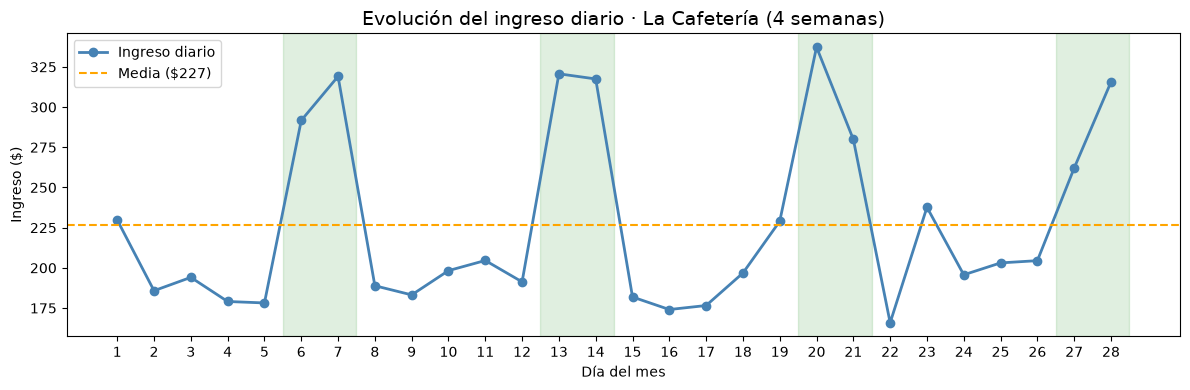

Las franjas verdes son los fines de semana: el ingreso sube notablemente.


In [21]:
# Gráfico de LÍNEA: es el tipo ideal para ver cómo evoluciona un valor a lo largo del tiempo.
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(dias, ingreso_diario, marker="o", linewidth=2,
        color="steelblue", label="Ingreso diario")

# Línea horizontal de la media → sirve de referencia visual
ax.axhline(ingreso_diario.mean(), color="orange", linestyle="--",
           linewidth=1.5, label=f"Media (${ingreso_diario.mean():.0f})")

# Sombrear los fines de semana para ver el patrón
for inicio in [6, 13, 20, 27]:
    ax.axvspan(inicio - 0.5, inicio + 1.5, alpha=0.12, color="green")

ax.set_title("Evolución del ingreso diario · La Cafetería (4 semanas)", fontsize=14)
ax.set_xlabel("Día del mes")
ax.set_ylabel("Ingreso ($)")
ax.legend()
ax.set_xticks(dias)
plt.tight_layout()
plt.show()
print("Las franjas verdes son los fines de semana: el ingreso sube notablemente.")

**Ejercicio 16.** Quiero comparar cuánto dinero generó cada producto en el mes.

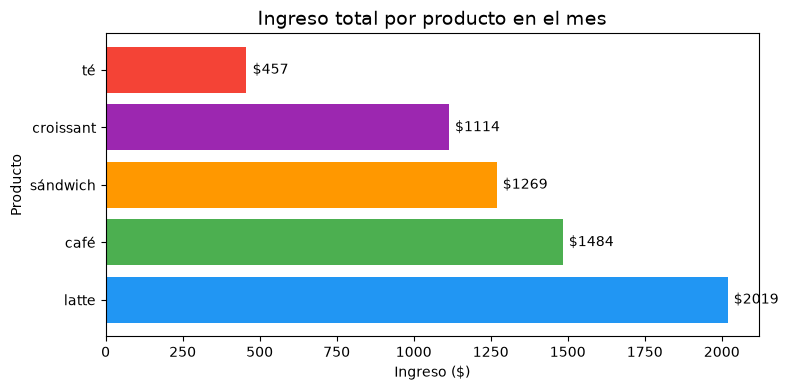

In [22]:
# Gráfico de BARRAS HORIZONTALES: ideal para comparar categorías.
# Las barras horizontales permiten leer bien los nombres aunque sean largos.
fig, ax = plt.subplots(figsize=(8, 4))

# Ordenamos de mayor a menor ingreso
orden = ingreso_por_producto.argsort()[::-1]
colores = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0", "#F44336"]

barras = ax.barh(productos[orden], ingreso_por_producto[orden], color=colores)

# Etiquetas con el valor exacto al final de cada barra
for barra, val in zip(barras, ingreso_por_producto[orden]):
    ax.text(barra.get_width() + 20, barra.get_y() + barra.get_height() / 2,
            f"${val:.0f}", va="center", fontsize=10)

ax.set_title("Ingreso total por producto en el mes", fontsize=14)
ax.set_xlabel("Ingreso ($)")
ax.set_ylabel("Producto")
plt.tight_layout()
plt.show()

**Ejercicio 17.** Quiero ver en un mismo gráfico las unidades vendidas cada día de los 5 productos, una línea por producto.

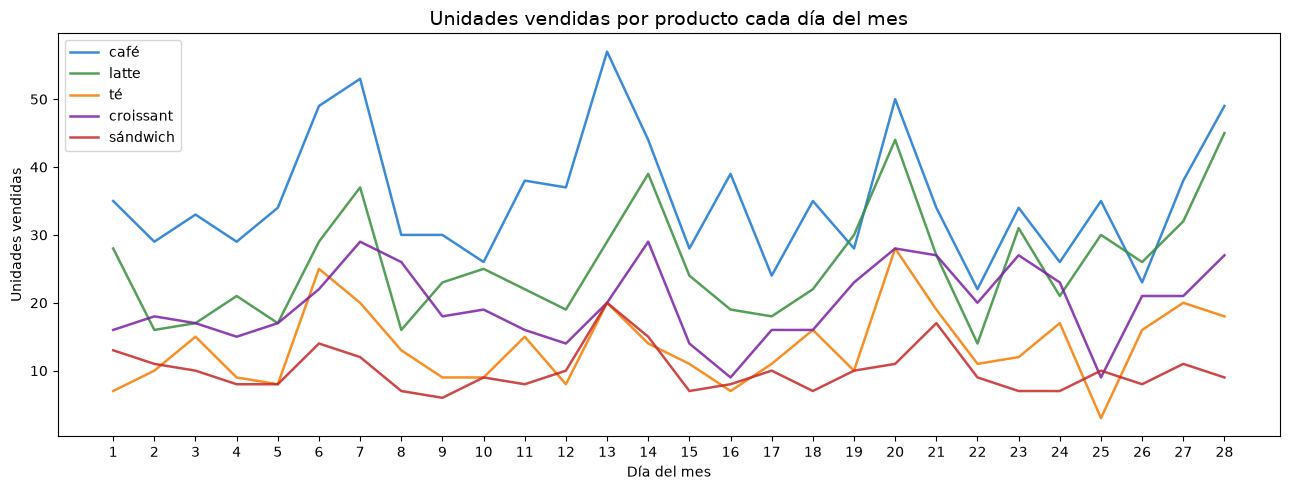

In [23]:
# Gráfico de LÍNEAS MÚLTIPLE: una línea por producto.
# Iteramos sobre las columnas de la matriz 'ventas' y asignamos un color a cada una.
fig, ax = plt.subplots(figsize=(13, 5))

colores_prods = ["#1976D2", "#388E3C", "#F57C00", "#7B1FA2", "#C62828"]

for i, (prod, color) in enumerate(zip(productos, colores_prods)):
    # ventas[:, i] → la columna i de la matriz = ventas diarias del producto i
    ax.plot(dias, ventas[:, i], label=prod, color=color, linewidth=1.8, alpha=0.85)

ax.set_title("Unidades vendidas por producto cada día del mes", fontsize=14)
ax.set_xlabel("Día del mes")
ax.set_ylabel("Unidades vendidas")
ax.legend(loc="upper left")
ax.set_xticks(dias)
plt.tight_layout()
plt.show()

**Ejercicio 18.** Quiero ver la matriz de ventas (días × productos) como un mapa de calor.

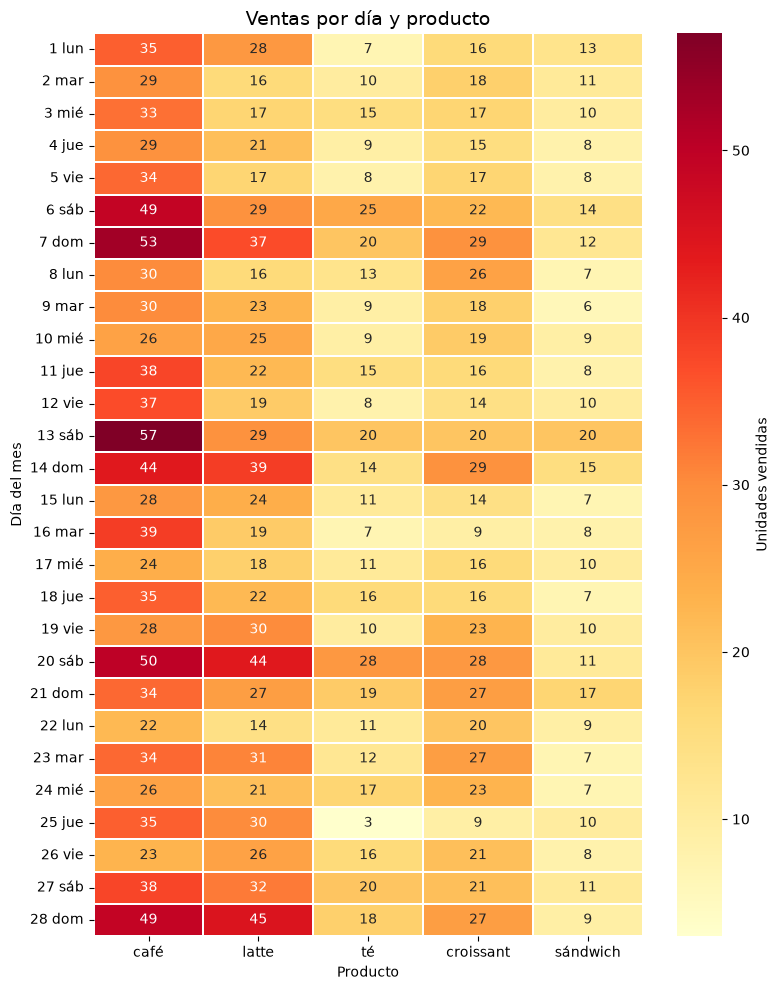

In [24]:
# Etiquetas de fila tipo "1 lun", "6 sáb", "7 dom"... (el día 1 fue lunes)
abreviaturas = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
dias = np.arange(1, 29)
etiquetas_dias = [f"{d} {abreviaturas[(d - 1) % 7]}" for d in dias]

fig, ax = plt.subplots(figsize=(8, 10))

sns.heatmap(
    ventas,
    ax=ax,
    cmap="YlOrRd",              # amarillo (pocas ventas) → rojo (muchas)
    annot=True, fmt="d",        # número exacto en cada celda
    linewidths=0.3,             # línea fina entre celdas
    xticklabels=productos,
    yticklabels=etiquetas_dias,
    cbar_kws={"label": "Unidades vendidas"},
)

ax.set_title("Ventas por día y producto", fontsize=14)
ax.set_xlabel("Producto")
ax.set_ylabel("Día del mes")
plt.tight_layout()
plt.show()

### Con los datos de las propinas 💵

Usa el DataFrame `propinas` tal como quedó al final de la Parte 2.

**Ejercicio 19.** Quiero ver el histograma del importe de la cuenta.

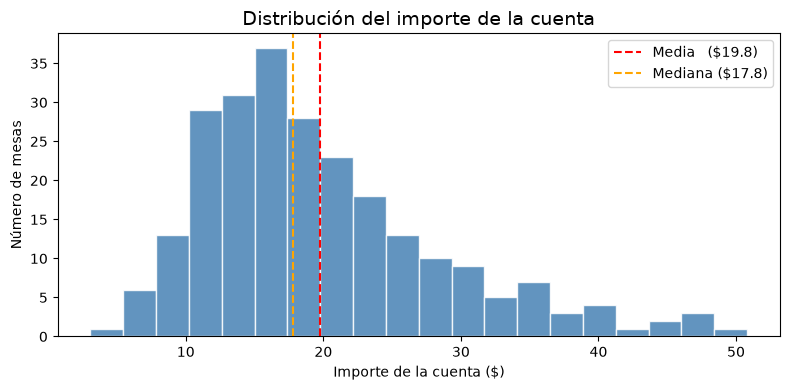

La distribución tiene 'cola' a la derecha: media > mediana por las cuentas altas.


In [25]:
# El histograma muestra la distribución de una variable numérica continua
# Cada barra agrupa los valores en un rango y muestra cuántos hay en ese rango
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(propinas["cuenta"], bins=20, color="steelblue",
        edgecolor="white", alpha=0.85)

# Media y mediana para contextualizar la distribución
ax.axvline(propinas["cuenta"].mean(),
           color="red",    linestyle="--",
           label=f"Media   (${propinas['cuenta'].mean():.1f})")
ax.axvline(propinas["cuenta"].median(),
           color="orange", linestyle="--",
           label=f"Mediana (${propinas['cuenta'].median():.1f})")

ax.set_title("Distribución del importe de la cuenta", fontsize=14)
ax.set_xlabel("Importe de la cuenta ($)")
ax.set_ylabel("Número de mesas")
ax.legend()
plt.tight_layout()
plt.show()
print("La distribución tiene 'cola' a la derecha: media > mediana por las cuentas altas.")

**Ejercicio 20.** Quiero visualizar la relación entre la cuenta y la propina.

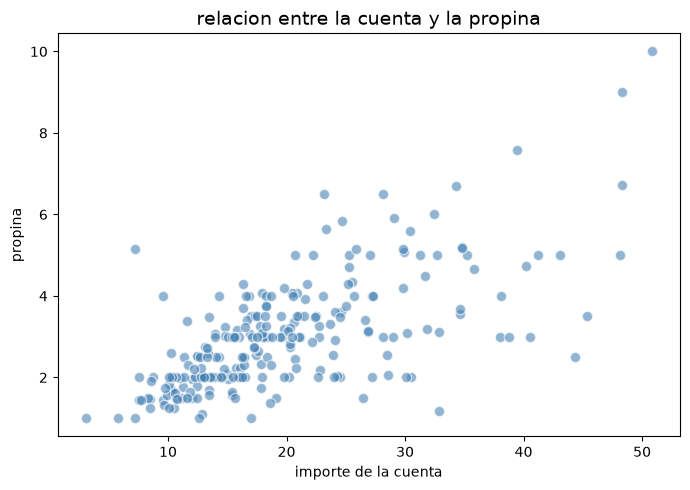

tendencia positiva clara a mayor cuenta, mayor propina


In [26]:
# El diagrama de dispersion muestra la relación entre dos variables numericas
# Si los puntos forman una nube diagonal → hay correlación
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(propinas["cuenta"], propinas["propina"],
           alpha=0.6, color="steelblue", edgecolors="white", s=55)

ax.set_title("relacion entre la cuenta y la propina", fontsize=14)
ax.set_xlabel("importe de la cuenta")
ax.set_ylabel("propina")
plt.tight_layout()
plt.show()
print("tendencia positiva clara a mayor cuenta, mayor propina")

**Ejercicio 21.** Quiero ver esa misma relación, pero distinguiendo las comidas de las cenas.

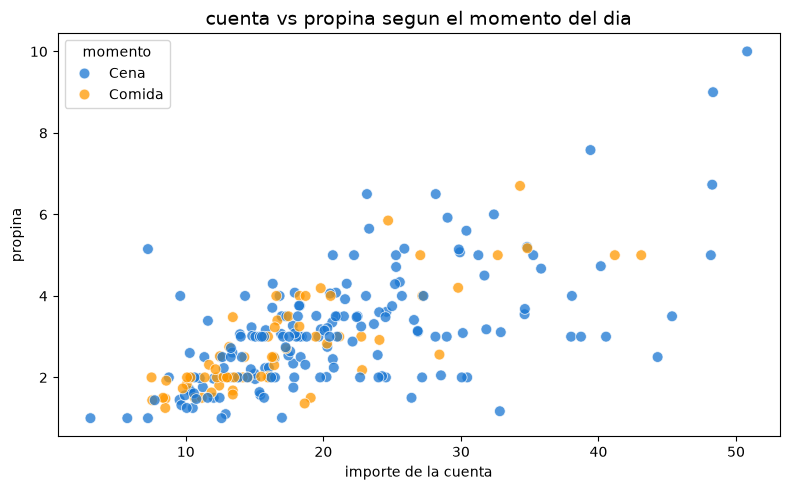

In [27]:
# el scater colorea los puntos segun una variable categorica
# asi vemos si el patron cuenta–propina cambia entre comidas y cenas
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=propinas,
    x="cuenta",
    y="propina",
    hue="momento",
    palette={"Comida": "#FF9800", "Cena": "#1976D2"},
    alpha=0.75,
    s=60,
    ax=ax,
)

ax.set_title("cuenta vs propina segun el momento del dia", fontsize=14)
ax.set_xlabel("importe de la cuenta")
ax.set_ylabel("propina")
ax.legend(title="momento")
plt.tight_layout()
plt.show()

**Ejercicio 22.** Quiero ver si hay valores atípicos en el porcentaje de propina de cada día de la semana.

C:\Users\alexa\AppData\Local\Temp\ipykernel_10444\2649043265.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


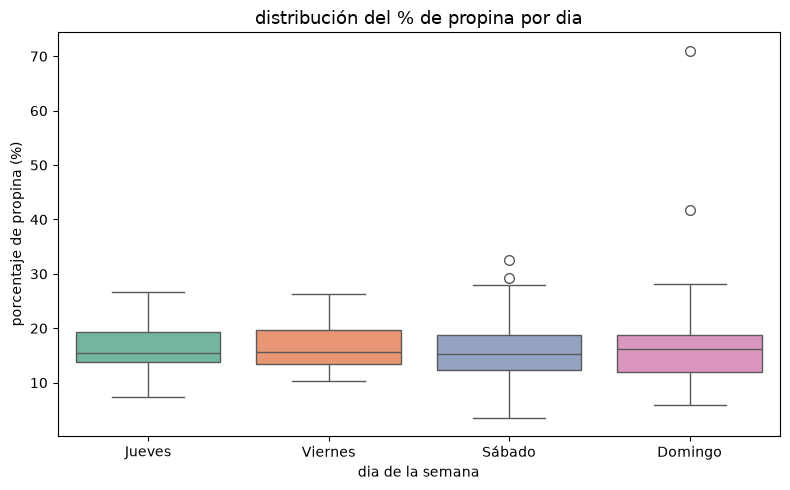

In [28]:
# el diagrama muestra la distribución y los valores atipicos
# la caja cubre el 50% central de los datos 
# y los puntos fuera de los bigotes son valores atipicos 
fig, ax = plt.subplots(figsize=(8, 5))

orden_dias = ["Jueves", "Viernes", "Sábado", "Domingo"]

sns.boxplot(
    data=propinas,
    x="dia",
    y="pct_propina",
    order=orden_dias,
    palette="Set2",
    flierprops=dict(marker="o", color="red", markersize=7),  # outliers en rojo
    ax=ax,
)

ax.set_title("distribución del % de propina por dia", fontsize=13)
ax.set_xlabel("dia de la semana")
ax.set_ylabel("porcentaje de propina (%)")
plt.tight_layout()
plt.show()

**Ejercicio 23.** Quiero ver cuántas mesas se atendieron cada día.

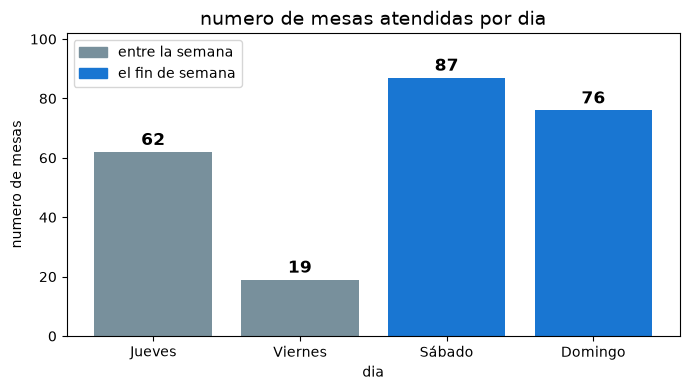

In [29]:
# grafico de barras para comparar cantidades entre las categorias
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(7, 4))

orden_dias = ["Jueves", "Viernes", "Sábado", "Domingo"]
conteo = propinas["dia"].value_counts().reindex(orden_dias)

barras = ax.bar(conteo.index, conteo.values,
                color=["#78909C", "#78909C", "#1976D2", "#1976D2"])

# numero exacto encima de cada barra
for barra in barras:
    ax.text(barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 1,
            str(int(barra.get_height())),
            ha="center", va="bottom", fontsize=12, fontweight="bold")

ax.set_title("numero de mesas atendidas por dia", fontsize=14)
ax.set_xlabel("dia")
ax.set_ylabel("numero de mesas")
ax.set_ylim(0, conteo.max() + 15)
ax.legend(handles=[
    Patch(color="#78909C", label="entre la semana"),
    Patch(color="#1976D2", label="el fin de semana"),
])
plt.tight_layout()
plt.show()

**Ejercicio 24.** Quiero comparar la propina media según el número de personas en la mesa, separando mesas de fumadores y de no fumadores.

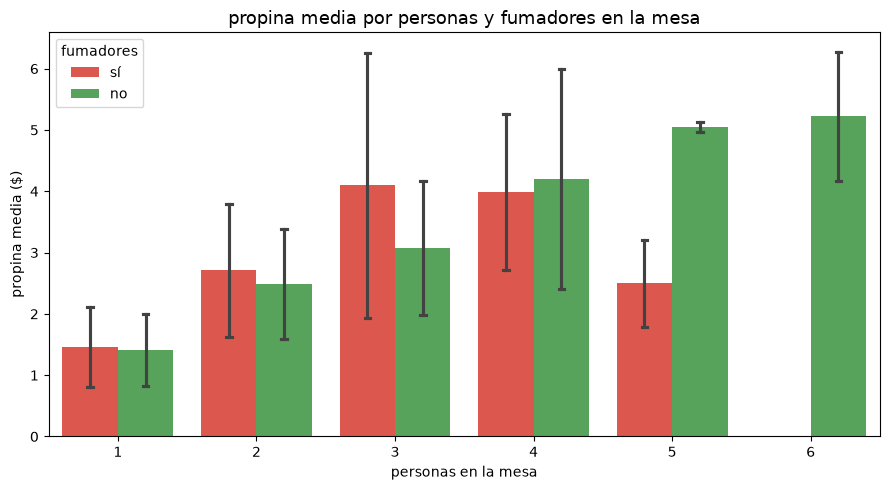

In [30]:
# se compara la propina media por dos variables categoricas simultaneamente
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=propinas,
    x="personas",
    y="propina",
    hue="fumador",
    palette={"sí": "#F44336", "no": "#4CAF50"},
    errorbar="sd",     # barras de error = desviación estandar
    capsize=0.08,
    ax=ax,
)

ax.set_title("propina media por personas y fumadores en la mesa", fontsize=13)
ax.set_xlabel("personas en la mesa")
ax.set_ylabel("propina media ($)")
ax.legend(title="fumadores")
plt.tight_layout()
plt.show()

### Con un dataset nuevo: los pingüinos 🐧

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies de la Antártida:

| Columna | Significado |
|---|---|
| `species` | especie: `Adelie`, `Chinstrap`, `Gentoo` |
| `island` | isla donde se registró |
| `bill_length_mm` | longitud del pico (mm) |
| `bill_depth_mm` | profundidad (altura) del pico (mm) |
| `flipper_length_mm` | longitud de la aleta (mm) |
| `body_mass_g` | peso (g) |
| `sex` | `Male` / `Female` |

**Ejercicio 25.** Carga los datos en un DataFrame llamado `pinguinos`. Quiero ver el histograma del peso de los pingüinos.

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female


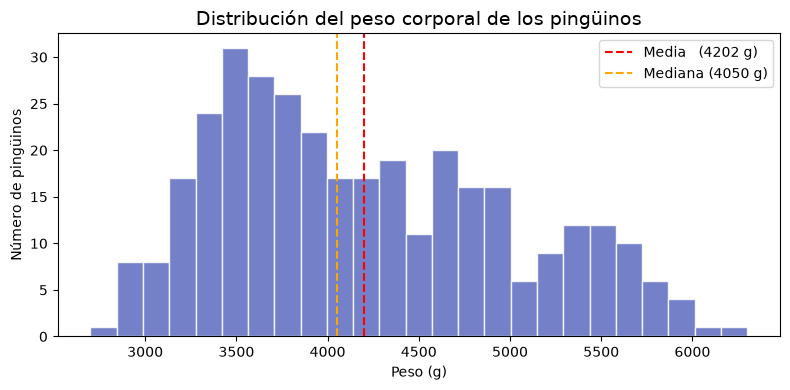

In [31]:
# Cargamos el CSV de pingüinos
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv")
print("Shape:", pinguinos.shape)
display(pinguinos.head(3))

# HISTOGRAMA del peso
fig, ax = plt.subplots(figsize=(8, 4))

# dropna() elimina los valores nulos antes de graficar
ax.hist(pinguinos["body_mass_g"].dropna(), bins=25,
        color="#5C6BC0", edgecolor="white", alpha=0.85)

ax.axvline(pinguinos["body_mass_g"].mean(),
           color="red",    linestyle="--",
           label=f"Media   ({pinguinos['body_mass_g'].mean():.0f} g)")
ax.axvline(pinguinos["body_mass_g"].median(),
           color="orange", linestyle="--",
           label=f"Mediana ({pinguinos['body_mass_g'].median():.0f} g)")

ax.set_title("Distribución del peso corporal de los pingüinos", fontsize=14)
ax.set_xlabel("Peso (g)")
ax.set_ylabel("Número de pingüinos")
ax.legend()
plt.tight_layout()
plt.show()

**Ejercicio 26.** Quiero ver si la distribución del peso cambia según la especie.

C:\Users\alexa\AppData\Local\Temp\ipykernel_10444\266394315.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Especie")


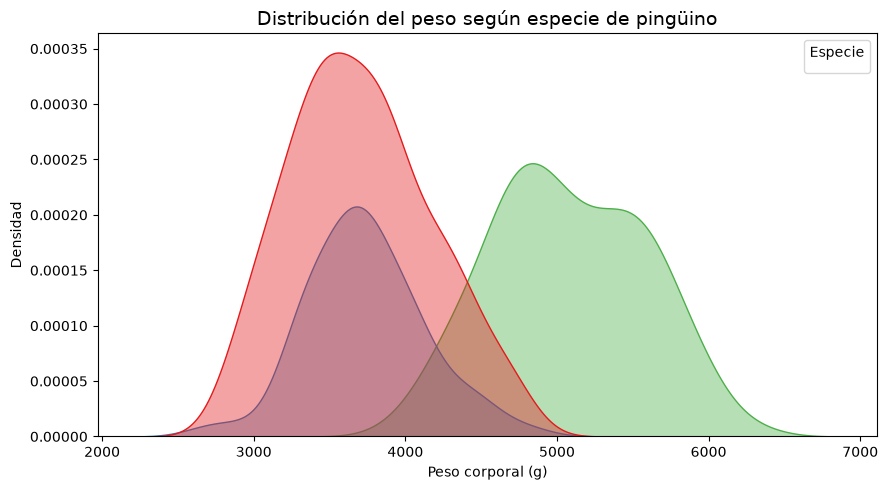

Los Gentoo son claramente más pesados; Adelie y Chinstrap se solapan bastante.


In [32]:
# GRÁFICO KDE (densidad de probabilidad): como un histograma suavizado.
# Con hue podemos comparar la distribución de cada especie en un mismo gráfico.
fig, ax = plt.subplots(figsize=(9, 5))

sns.kdeplot(
    data=pinguinos,
    x="body_mass_g",
    hue="species",     # una curva por especie
    fill=True,         # rellena el área bajo la curva
    alpha=0.4,
    palette="Set1",
    ax=ax,
)

ax.set_title("Distribución del peso según especie de pingüino", fontsize=14)
ax.set_xlabel("Peso corporal (g)")
ax.set_ylabel("Densidad")
ax.legend(title="Especie")
plt.tight_layout()
plt.show()
print("Los Gentoo son claramente más pesados; Adelie y Chinstrap se solapan bastante.")

**Ejercicio 27.** Quiero ver si hay valores atípicos en la longitud de la aleta de cada especie.

C:\Users\alexa\AppData\Local\Temp\ipykernel_10444\980478136.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


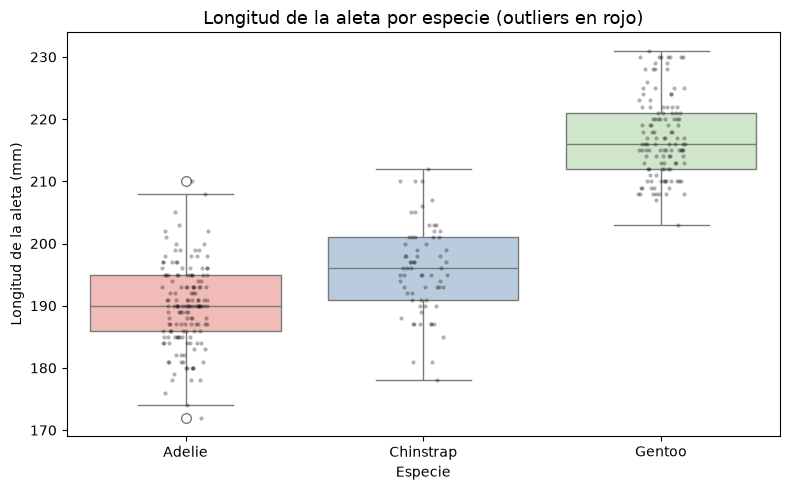

In [33]:
# BOXPLOT + STRIPPLOT superpuesto:
# El boxplot muestra la distribución y los outliers.
# El stripplot añade cada punto individual → vemos si hay muchos o pocos datos.
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=pinguinos,
    x="species",
    y="flipper_length_mm",
    palette="Pastel1",
    flierprops=dict(marker="o", color="red", markersize=7),
    ax=ax,
)
sns.stripplot(
    data=pinguinos,
    x="species",
    y="flipper_length_mm",
    color="black",
    alpha=0.3,
    size=3,
    jitter=True,   # dispersa los puntos para que no se solapen
    ax=ax,
)

ax.set_title("Longitud de la aleta por especie (outliers en rojo)", fontsize=13)
ax.set_xlabel("Especie")
ax.set_ylabel("Longitud de la aleta (mm)")
plt.tight_layout()
plt.show()

**Ejercicio 28.** Quiero visualizar la relación entre la longitud y la profundidad del pico, distinguiendo las especies.

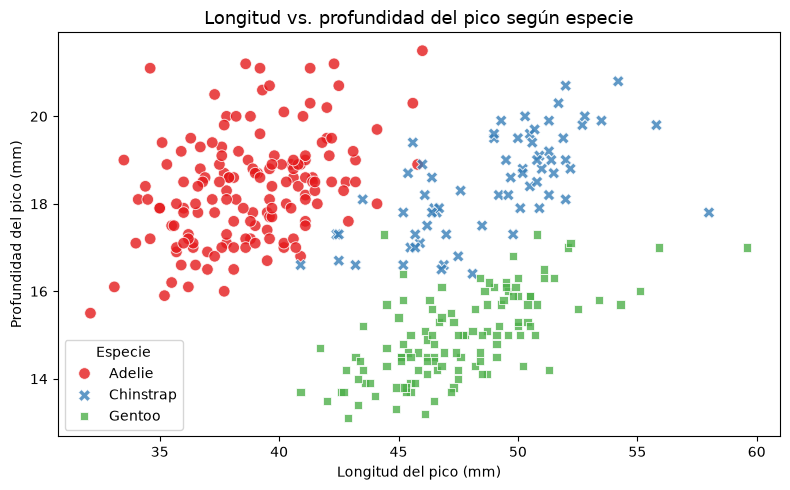

Las tres especies forman nubes bien separadas → son buenos predictores para ML.


In [34]:
# SCATTER con hue y style:
# hue cambia el color por especie, style cambia el marcador.
# Así podemos distinguir las especies incluso en blanco y negro.
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=pinguinos,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    style="species",
    palette="Set1",
    alpha=0.8,
    s=70,
    ax=ax,
)

ax.set_title("Longitud vs. profundidad del pico según especie", fontsize=13)
ax.set_xlabel("Longitud del pico (mm)")
ax.set_ylabel("Profundidad del pico (mm)")
ax.legend(title="Especie")
plt.tight_layout()
plt.show()
print("Las tres especies forman nubes bien separadas → son buenos predictores para ML.")

**Ejercicio 29.** Quiero ver en una sola figura el histograma de las cuatro medidas numéricas, cada una en su propio gráfico.

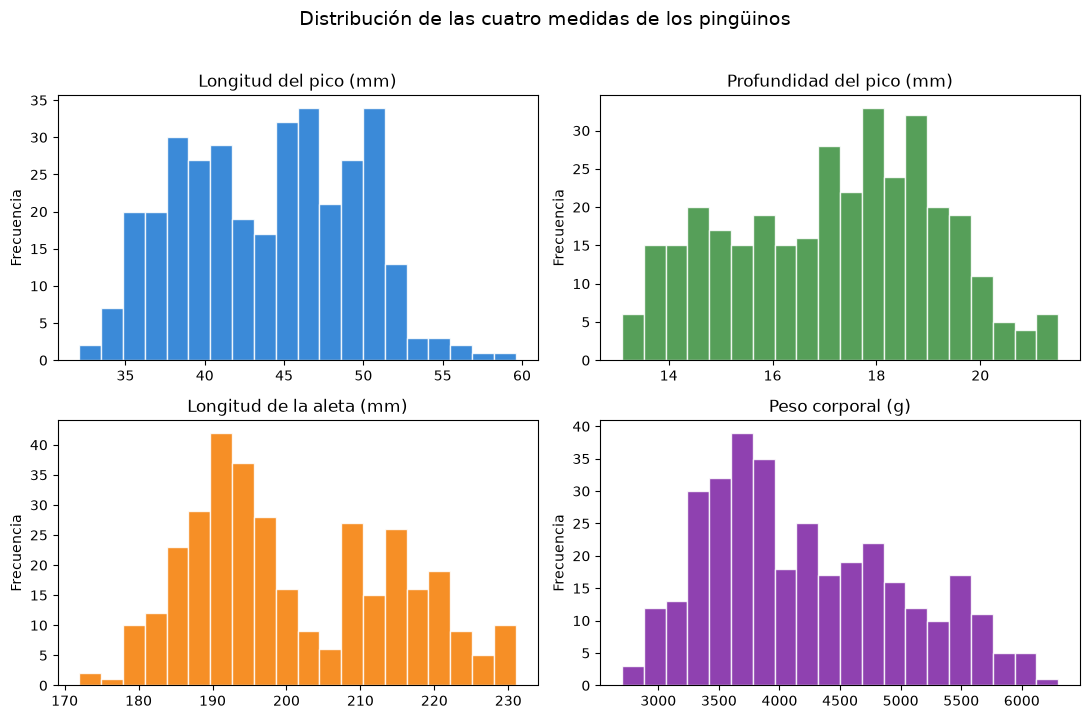

In [35]:
# SUBPLOTS: múltiples gráficos en una misma figura.
# plt.subplots(2, 2) crea una cuadrícula de 2 filas × 2 columnas.
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
titulos = ["Longitud del pico (mm)", "Profundidad del pico (mm)",
           "Longitud de la aleta (mm)", "Peso corporal (g)"]
colores = ["#1976D2", "#388E3C", "#F57C00", "#7B1FA2"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes = axes.ravel()  # convierte la cuadrícula 2D en una lista plana de 4 ejes

for ax, col, titulo, color in zip(axes, medidas, titulos, colores):
    ax.hist(pinguinos[col].dropna(), bins=20, color=color,
            edgecolor="white", alpha=0.85)
    ax.set_title(titulo, fontsize=12)
    ax.set_ylabel("Frecuencia")

fig.suptitle("Distribución de las cuatro medidas de los pingüinos",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Ejercicio 30.** Quiero ver qué medidas numéricas están más relacionadas entre sí.

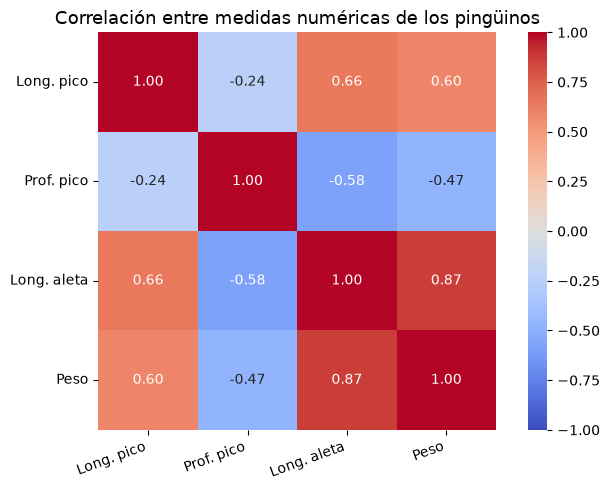

Longitud de aleta y peso tienen correlación muy alta (+0.87):
los pingüinos más pesados tienen aletas más largas.
La profundidad del pico correlaciona negativamente con las otras medidas.


In [36]:
# MAPA DE CALOR de la MATRIZ DE CORRELACIÓN:
# La correlación va de -1 (relación inversa) a +1 (relación directa).
# 0 = sin relación lineal.

numericas = pinguinos[["bill_length_mm", "bill_depth_mm",
                        "flipper_length_mm", "body_mass_g"]]

# .corr() calcula la correlación de Pearson entre cada par de columnas
correlaciones = numericas.corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    correlaciones,
    annot=True,          # valor numérico en cada celda
    fmt=".2f",           # dos decimales
    cmap="coolwarm",     # azul = correlación negativa, rojo = positiva
    vmin=-1, vmax=1,     # escala fija de -1 a 1
    square=True,
    ax=ax,
)

etiquetas = ["Long. pico", "Prof. pico", "Long. aleta", "Peso"]
ax.set_xticklabels(etiquetas, rotation=20, ha="right")
ax.set_yticklabels(etiquetas, rotation=0)
ax.set_title("Correlación entre medidas numéricas de los pingüinos", fontsize=13)
plt.tight_layout()
plt.show()

print("Longitud de aleta y peso tienen correlación muy alta (+0.87):")
print("los pingüinos más pesados tienen aletas más largas.")
print("La profundidad del pico correlaciona negativamente con las otras medidas.")

**Ejercicio 31.** Quiero comparar el peso medio de cada especie, separando machos y hembras.

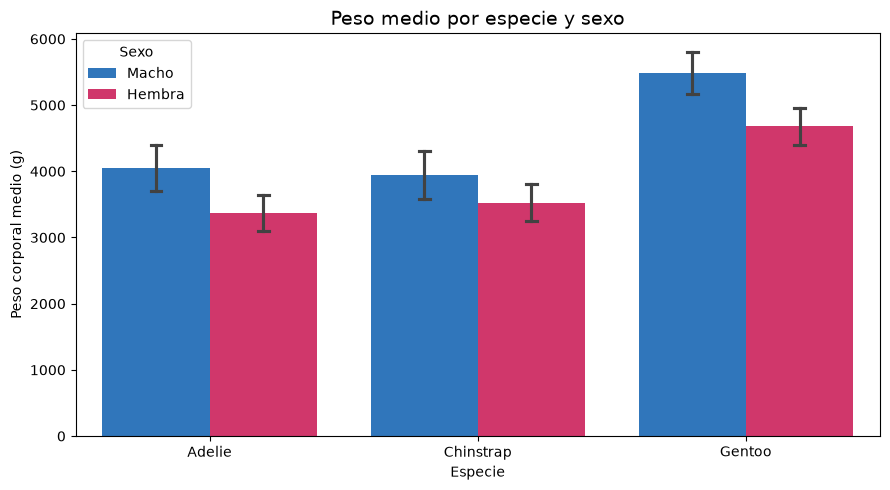

En las tres especies los machos son más pesados que las hembras.
Los Gentoo son los más pesados independientemente del sexo.


In [37]:
# BARPLOT AGRUPADO: compara el peso medio por especie Y sexo al mismo tiempo.
# Primero eliminamos las filas donde sex o body_mass_g son nulos.
pinguinos_sin_na = pinguinos.dropna(subset=["sex", "body_mass_g"])

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=pinguinos_sin_na,
    x="species",
    y="body_mass_g",
    hue="sex",
    palette={"Male": "#1976D2", "Female": "#E91E63"},
    errorbar="sd",      # barras de error = desviación estándar
    capsize=0.08,
    ax=ax,
)

ax.set_title("Peso medio por especie y sexo", fontsize=14)
ax.set_xlabel("Especie")
ax.set_ylabel("Peso corporal medio (g)")

# Cambiamos las etiquetas de la leyenda al español
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Macho", "Hembra"], title="Sexo")

plt.tight_layout()
plt.show()

print("En las tres especies los machos son más pesados que las hembras.")
print("Los Gentoo son los más pesados independientemente del sexo.")